# Load data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
figsize=(20, 8)

df2 = pd.concat([
    pd.read_csv('results_20261025_225531/all_results.csv'),
    pd.read_csv('results_20261025_183402/all_results.csv'),
    pd.read_csv('results_20261025_162053/all_results.csv')
], ignore_index=True)

df2 = df2[df2['feature'] == 'Continent']
df = pd.read_csv('results_20261027_101142/all_results.csv')
df = pd.concat([df , df2[df2['embedding'].isin(['pca' ,'lle' ,'wavelet' ,'fft' ,'autoencoder' ,'umap' ,'nnclr_cnn', 'nnclr_lstm',
 'TiViT-CLIP-B16', 'TiViT-CLIP-H14', 'TS2Vec',
 'Chronos-T5-small' ,'Chronos-Bolt-base'])]])
df = df[df['classifier'] != 'mlp']
print(f'Embedding methods : {df['embedding'].unique()}')

Embedding methods : ['No-embed' 'pca' 'lle' 'wavelet' 'fft' 'autoencoder' 'umap' 'nnclr_cnn'
 'nnclr_lstm' 'TiViT-CLIP-B16' 'TiViT-CLIP-H14' 'TiViT+MantisV2' 'TS2Vec'
 'Chronos-T5-small' 'Chronos-Bolt-base' 'Mantis-8M' 'MantisPlus'
 'Mantis-Utica' 'MantisV2' 'Mantis-8M_pretrain_continued'
 'MantisPlus_pretrain_continued' 'Mantis-Utica_pretrain_continued'
 'MantisV2_pretrain_continued' 'Mantis-8M_pretrain_scratch'
 'MantisV2_pretrain_scratch' 'graph' 'tda']


In [11]:
categories = {
    'Baseline': ['No-embed'],
    'Dimensionality reduction': ['pca', 'lle', 'umap'],
    'Signal / topological / graph': ['wavelet', 'fft', 'tda', 'graph'],
    'Learned (self-supervised)': ['autoencoder', 'nnclr_cnn', 'nnclr_lstm', 'TS2Vec'],
    'Foundation models': [
        'TiViT-CLIP-B16', 'TiViT-CLIP-H14', 'TiViT+MantisV2',
        'Chronos-T5-small', 'Chronos-Bolt-base',
        'Mantis-8M', 'MantisPlus', 'Mantis-Utica', 'MantisV2',
    ],
    'Mantis: continued pretraining': [
        'Mantis-8M_pretrain_continued', 'MantisPlus_pretrain_continued',
        'Mantis-Utica_pretrain_continued', 'MantisV2_pretrain_continued',
    ],
    'Mantis: pretrained from scratch': [
        'Mantis-8M_pretrain_scratch', 'MantisV2_pretrain_scratch',
    ],
}

# 2. One color per category
cat_colors = dict(zip(categories, sns.color_palette("tab10", len(categories))))

# 3. embedding -> color, and the x order (grouped by category)
emb_colors = {emb: cat_colors[cat] for cat, embs in categories.items() for emb in embs}
order = [emb for embs in categories.values() for emb in embs]
order = [e for e in order if e in df['embedding'].unique()]  # drop any missing ones

# Analyse classification per event type

In [6]:
df_event = df[df['feature'] == 'event_type']

## Best and worst scores per window size

In [9]:
for window in [7,14,30]:
    df_window = df_event[df_event['window'] == window]
    
    print(f'\nBest accuracy when classified using a {window} days window (feature = event_type):')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].max()].iterrows():
        print(f'    - feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    print(f'\nWorst accuracy when classified using a {window} days window (feature = event_type):')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].min()].iterrows():
        print(f'    - feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    


Best accuracy when classified using a 7 days window (feature = event_type):
    - feature = event_type, embedding method = MantisPlus, classifier = logreg, accuracy = 0.778

Worst accuracy when classified using a 7 days window (feature = event_type):
    - feature = event_type, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.414

Best accuracy when classified using a 14 days window (feature = event_type):
    - feature = event_type, embedding method = Chronos-T5-small, classifier = logreg, accuracy = 0.843

Worst accuracy when classified using a 14 days window (feature = event_type):
    - feature = event_type, embedding method = Mantis-8M_pretrain_continued, classifier = dt, accuracy = 0.471

Best accuracy when classified using a 30 days window (feature = event_type):
    - feature = event_type, embedding method = Chronos-T5-small, classifier = logreg, accuracy = 0.854
    - feature = event_type, embedding method = Mantis-8M, classifier = svm, accuracy = 0.854

Worst acc

##  Mean accuracy vs. window size

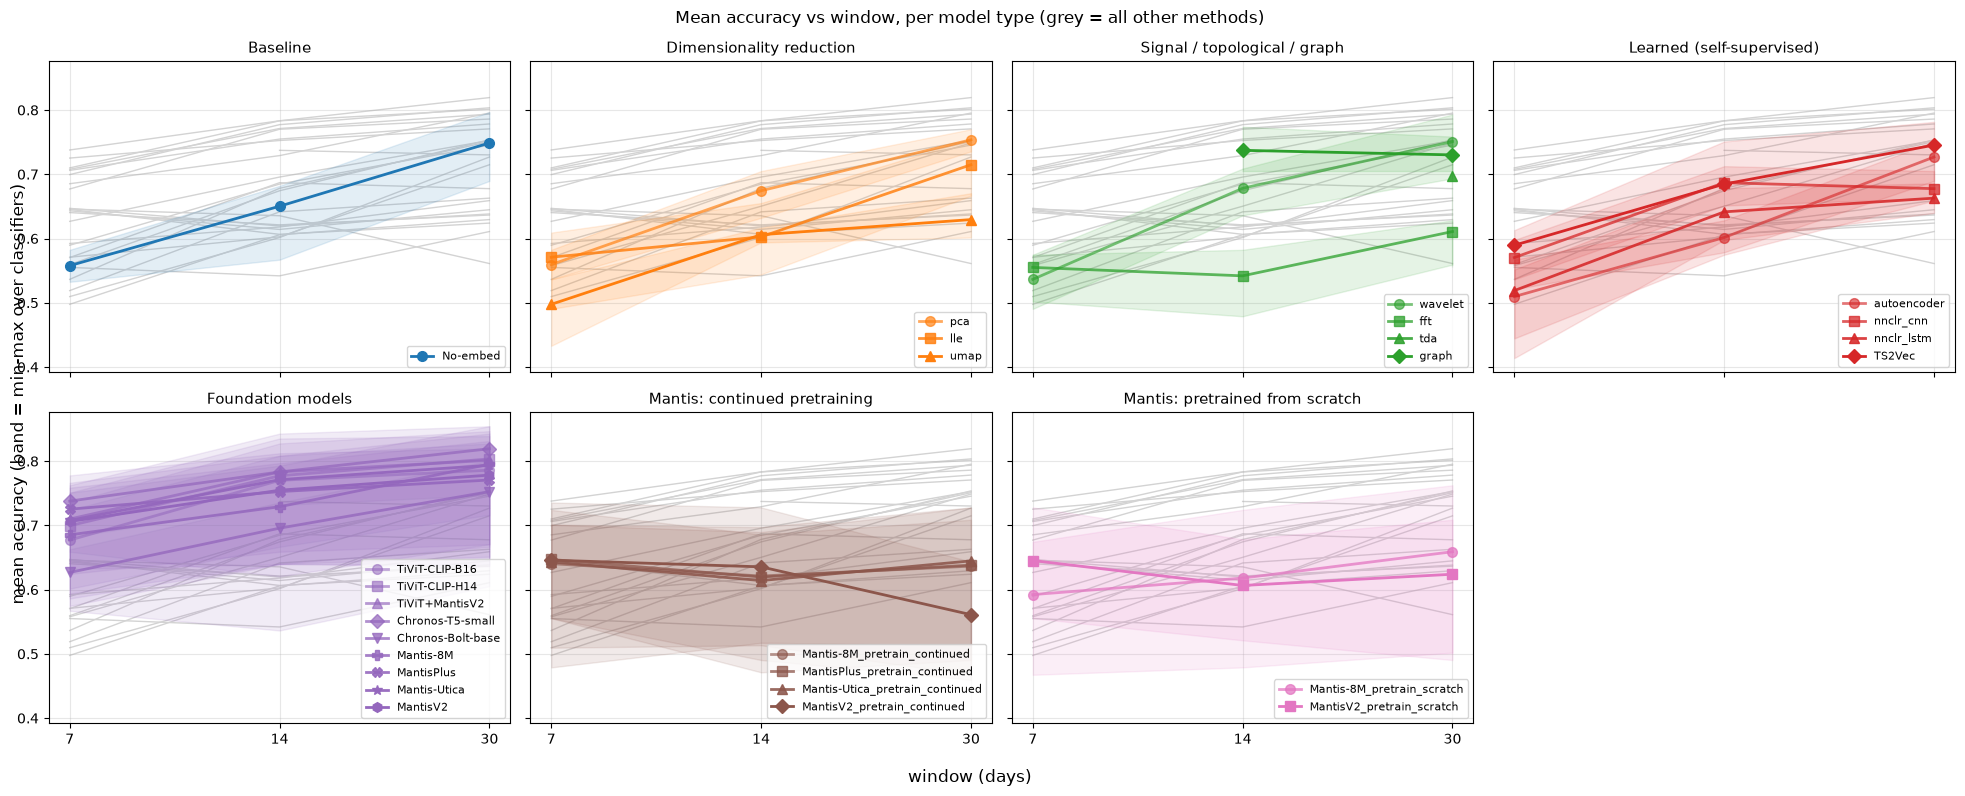

In [12]:

stats = (df_event
         .groupby(['embedding', 'window'])['accuracy']
         .agg(['mean', 'min', 'max'])
         .reset_index())

pivot_mean = stats.pivot(index='window', columns='embedding', values='mean')
pivot_min  = stats.pivot(index='window', columns='embedding', values='min')
pivot_max  = stats.pivot(index='window', columns='embedding', values='max')

windows = list(pivot_mean.index)          # [7, 14, 30]
x = np.arange(len(windows))
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

ncols = 4
nrows = int(np.ceil(len(categories) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                         sharex=True, sharey=True)
axes = axes.ravel()

SHOW_BAND = True   # min-max range across classifiers

for ax, (cat, embs) in zip(axes, categories.items()):
    # all other methods in light grey for context
    for emb in pivot_mean.columns:
        if emb not in embs:
            ax.plot(x, pivot_mean[emb], color='lightgrey', lw=1, zorder=1)

    for j, emb in enumerate([e for e in embs if e in pivot_mean.columns]):
        if SHOW_BAND:
            ax.fill_between(x, pivot_min[emb], pivot_max[emb],
                            color=cat_colors[cat], alpha=0.12, zorder=2)
        ax.plot(x, pivot_mean[emb], color=cat_colors[cat], lw=2,
                marker=markers[j % len(markers)], ms=7,
                alpha=0.5 + 0.5 * (j + 1) / len(embs),
                label=emb, zorder=3)

    ax.set_title(cat, fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(windows)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')

for ax in axes[len(categories):]:
    ax.set_visible(False)

fig.supxlabel('window (days)')
fig.supylabel('mean accuracy (band = min-max over classifiers)')
fig.suptitle('Mean accuracy vs window, per model type (grey = all other methods)')
plt.tight_layout()
plt.show()

## Best accuracy vs. window size

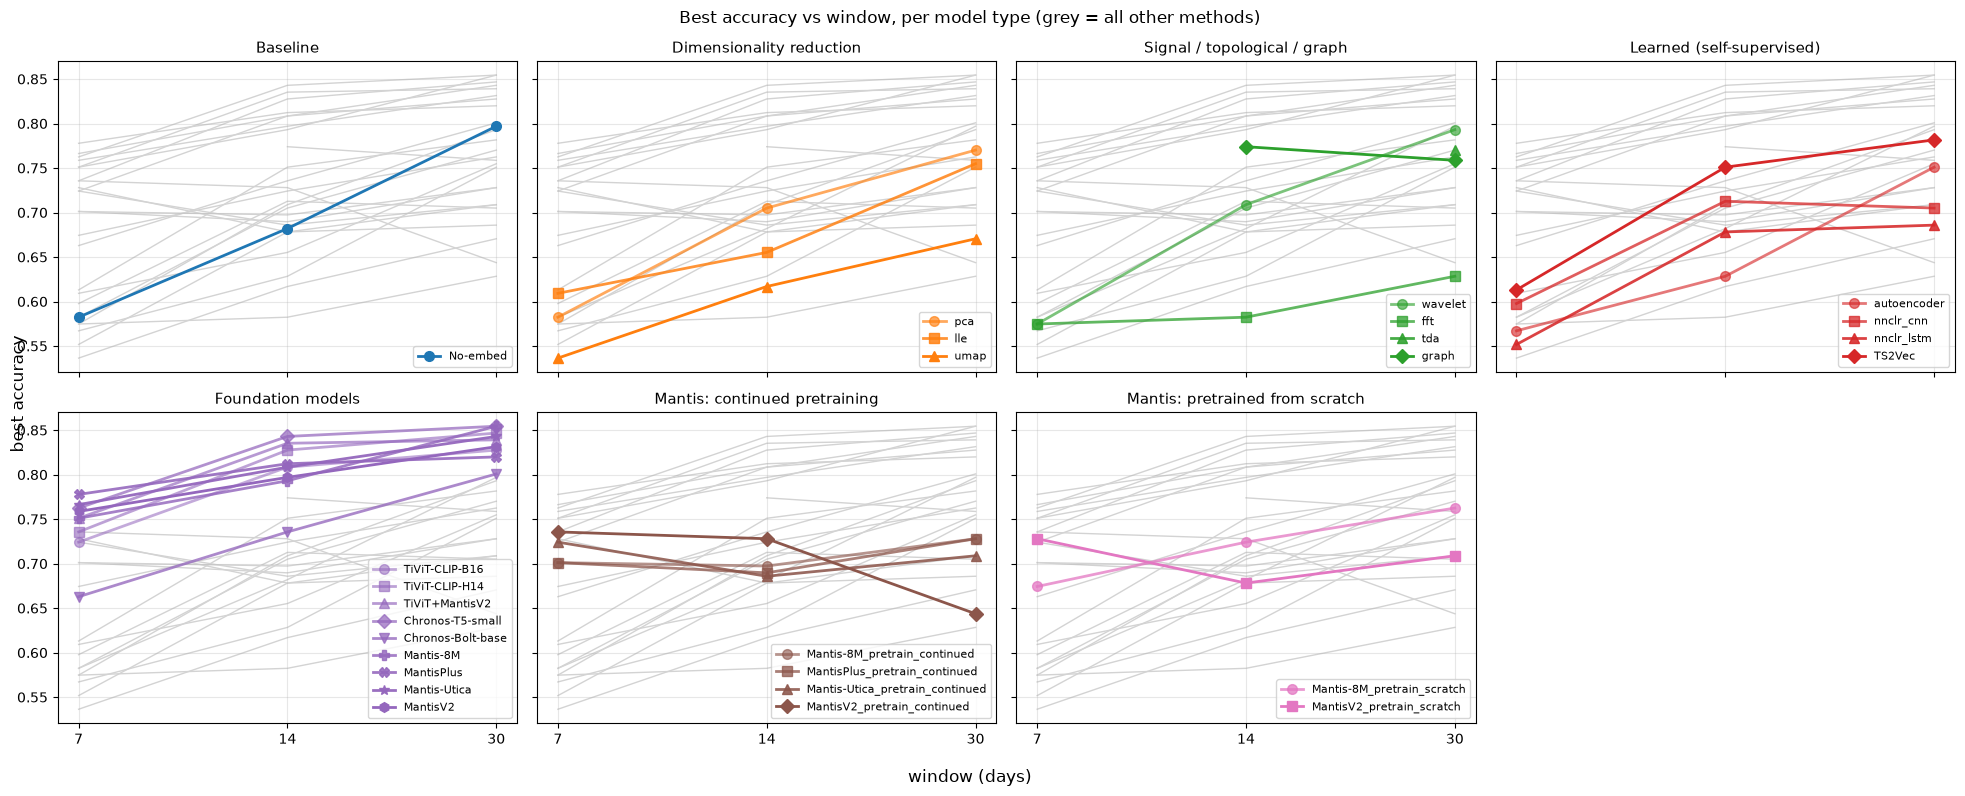

In [13]:
df_best = (df_event
           .groupby(['embedding', 'window'])['accuracy'].max().reset_index())
pivot = df_best.pivot(index='window', columns='embedding', values='accuracy')
windows = list(pivot.index)                      # [7, 14, 30]
x = np.arange(len(windows))                      # evenly spaced ticks (7 -> 14 -> 30 is not linear)

markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

ncols = 4
nrows = int(np.ceil(len(categories) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                         sharex=True, sharey=True)
axes = axes.ravel()

for ax, (cat, embs) in zip(axes, categories.items()):
    # all other methods in light grey for context
    for emb in pivot.columns:
        if emb not in embs:
            ax.plot(x, pivot[emb], color='lightgrey', lw=1, zorder=1)

    # methods of this category in color
    for j, emb in enumerate([e for e in embs if e in pivot.columns]):
        ax.plot(x, pivot[emb], color=cat_colors[cat], lw=2,
                marker=markers[j % len(markers)], ms=7,
                alpha=0.5 + 0.5 * (j + 1) / len(embs),   # slight shade variation
                label=emb, zorder=3)

    ax.set_title(cat, fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(windows)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')

for ax in axes[len(categories):]:                # hide unused panels
    ax.set_visible(False)

fig.supxlabel('window (days)')
fig.supylabel('best accuracy')
fig.suptitle('Best accuracy vs window, per model type (grey = all other methods)')
plt.tight_layout()
plt.show()

## Accuracy per classifier and embedding

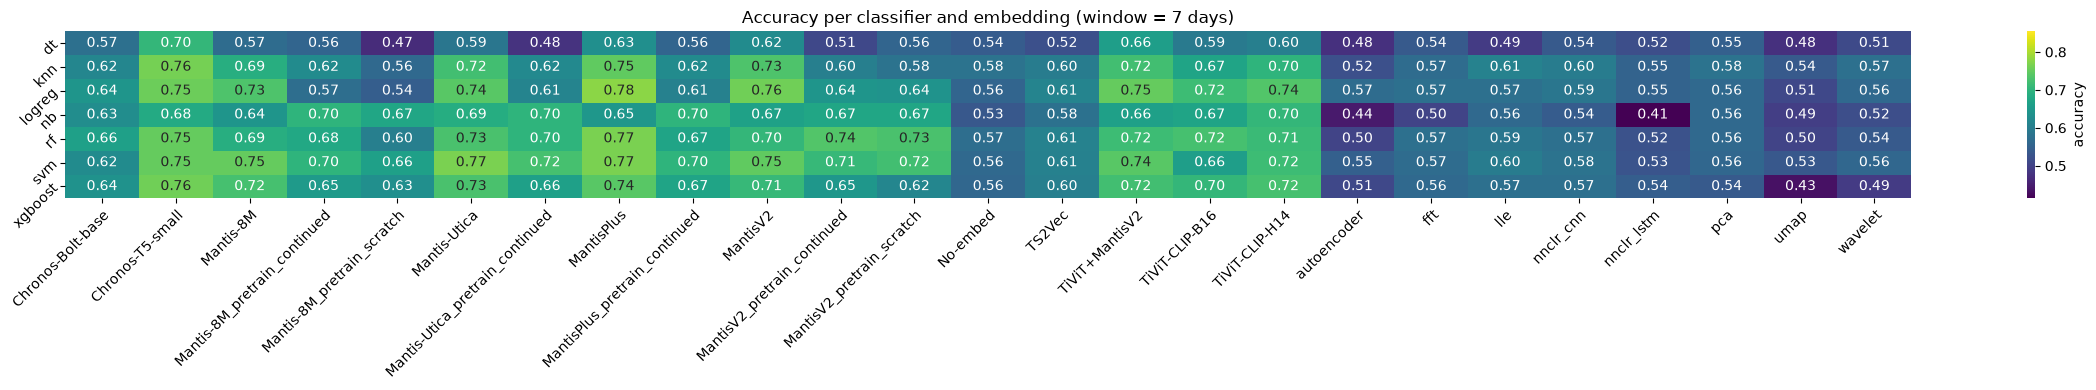

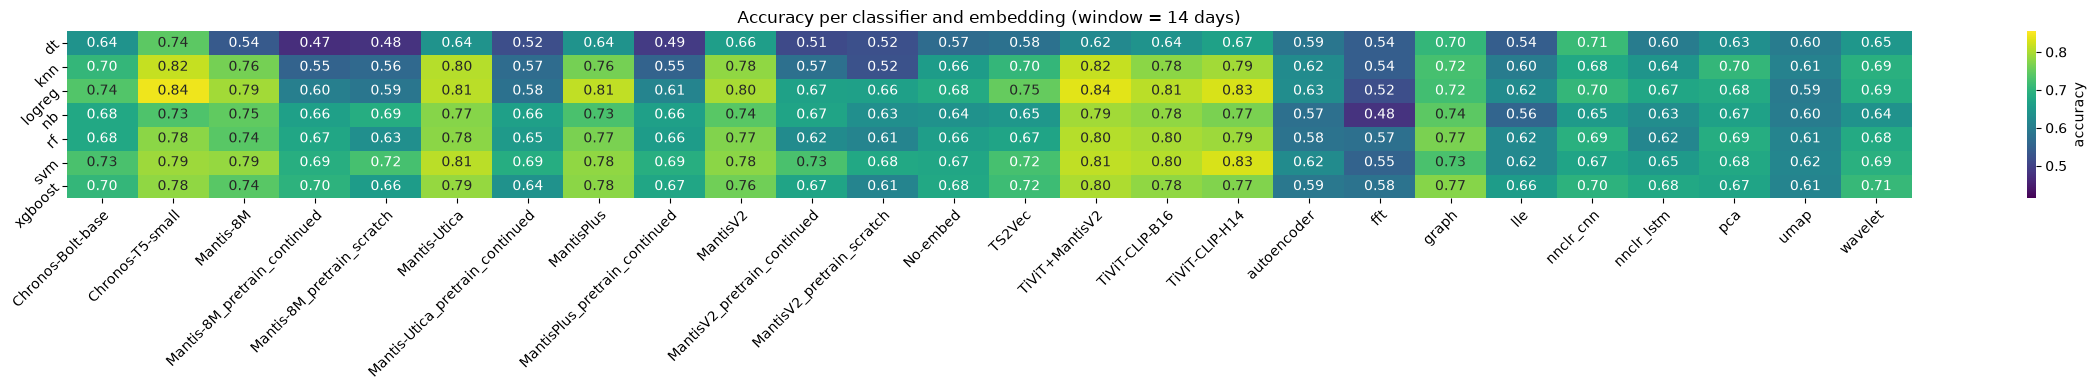

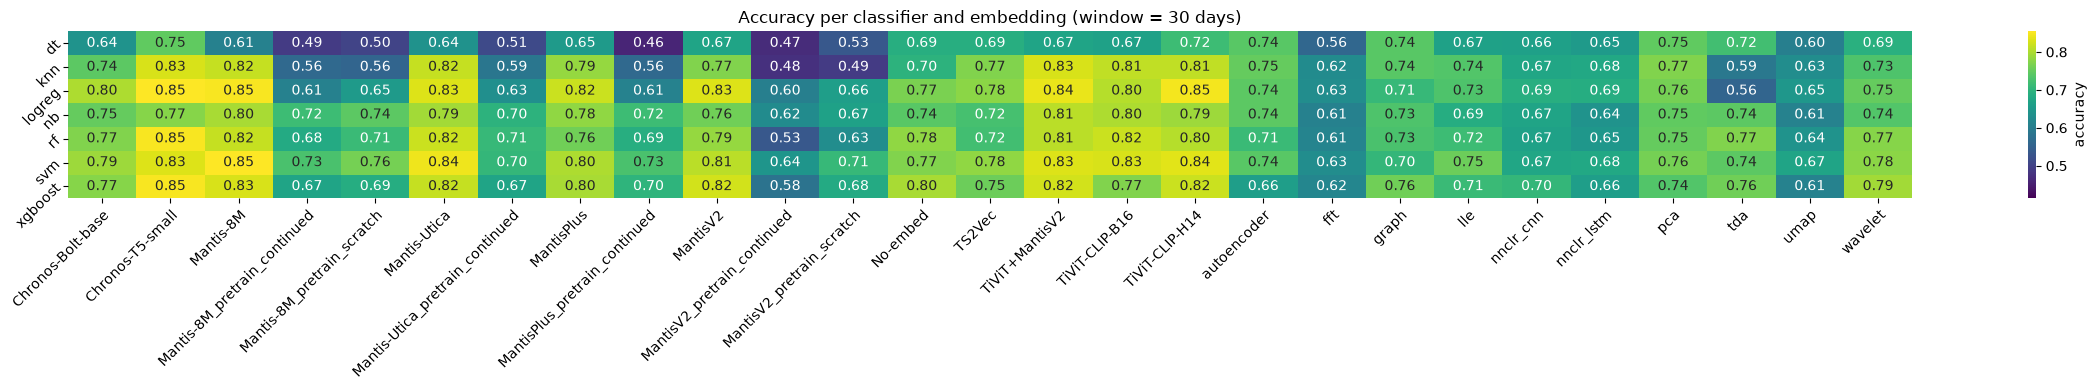

In [14]:
min_acc = df_event['accuracy'].min()
max_acc = df_event['accuracy'].max()
# reuses `order` from the earlier snippet (embeddings grouped by category)
for w in [7, 14, 30]:
    pivot = (
        df_event[df_event['window'] == w]
        .pivot_table(index='classifier', columns='embedding', values='accuracy')
        #.reindex(columns=[e for e in order if e in df_event['embedding'].unique()])
    ).dropna()

    fig, ax = plt.subplots(figsize=(24, 4))
    sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f", ax=ax,
                cbar_kws={"label": "accuracy"}, vmin=min_acc, vmax= max_acc)
    ax.set_title(f"Accuracy per classifier and embedding (window = {w} days)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.setp(ax.get_yticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()